# 第4章　テスト粒子で円盤銀河を作る
**完成版 / v2.7**

本章には任意演習のコードセルはありません。本文のTODOを解答してから上から実行してください。標準結果は `validation.json` に保存し、`exercise_validation.json` の状態は `not_applicable` とします。条件を変えたらカーネルを再起動し、上から実行し直してください。

第3章の固定Plummer場と台形則を再利用し、**線形補間と乱数**で指数円盤を作ります。
多数の粒子をKDKで同時に動かしますが、粒子間の重力は計算しません。
$M$はPlummer球の質量、$R_d$は粒子の分布、$R_{\max}$は初期粒子を配置する範囲です。

計算条件・図・実装は本教材用に設定しています。理論の導出と出典は本文PDFを参照してください。
**実行：** カーネルを再起動して上から実行します。パラメータを変えたときも全セルを再実行します。
NumPyとMatplotlibを使います。最後の動画表示だけはIPythonを使います。

In [1]:
from pathlib import Path
from time import perf_counter
import json
import numpy as np
import matplotlib.pyplot as plt

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass

ROOT = Path.cwd() / "output" / "chap04"
ROOT.mkdir(parents=True, exist_ok=True)
FIGDIR, DATADIR = ROOT / "figures", ROOT / "data"
FIGDIR.mkdir(exist_ok=True)
DATADIR.mkdir(exist_ok=True)

# 標準結果と任意演習の結果を分けて保存します。上から再実行すると登録を初期化します。
exercise_results = {}


def save_exercise_results():
    def json_value(value):
        if isinstance(value, np.ndarray):
            return value.tolist()
        if isinstance(value, np.generic):
            return value.item()
        if isinstance(value, dict):
            return {key: json_value(item) for key, item in value.items()}
        if isinstance(value, (list, tuple)):
            return [json_value(item) for item in value]
        return value
    record = {"status": "completed" if exercise_results else "not_applicable", "results": json_value(exercise_results)}
    _ = (DATADIR / "exercise_validation.json").write_text(json.dumps(record, ensure_ascii=False, indent=2), encoding="utf-8")


save_exercise_results()
IN_NOTEBOOK = "get_ipython" in globals()
BLUE, VERMILLION, GREEN, GRAY = "#0072B2", "#D55E00", "#009E73", "#777777"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white"})
MAKE_ANIMATION = IN_NOTEBOOK


def save_figure(fig, name):
    fig.savefig(FIGDIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIGDIR / f"{name}.png", dpi=170, bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)

## 1. 円盤の分布と、重力を作る球を区別する
位置は$x$–$y$平面です。$R=\sqrt{x^2+y^2}$とします。
粒子数面密度を$\Sigma_N(R)=\Sigma_{N,0}\exp(-R/R_d)$と置くと、半径の確率密度は
$$p_R(R)=\frac{R\exp(-R/R_d)}{R_d^2 C(x_{\max})},\qquad C(x_{\max})=1-(1+x_{\max})e^{-x_{\max}},\quad x_{\max}=R_{\max}/R_d.$$
これは$0\leq R\leq R_{\max}$で規格化した**初期分布**です。
表の区間数`n_cdf`、粒子数`n_particles`、時間刻み`dt`を区別します。

In [2]:
KM_S_TO_KPC_GYR = 1.0227121650537077
G = 4.30091e-6 * KM_S_TO_KPC_GYR**2  # kpc^3 / (Msun Gyr^2)
mass, a = 1.0e11, 3.0              # Plummer球の質量 [Msun] とスケール長 [kpc]
rd, rmax = 3.0, 15.0               # 粒子分布のスケール長と初期外縁 [kpc]
n_particles = 1000
n_cdf = 4096                      # CDF表の区間数。分点数は4097です。
seed, spin = 42, +1                # +1は反時計回り、-1は時計回りです。
t_end, n_steps = 0.60, 3000        # [Gyr]。dt = 0.2 Myrです。
save_every = 10                    # 時間刻みではなく、履歴の保存間隔です。
dt = t_end / n_steps


def check_positive(value, name):
    if not np.isfinite(value) or value <= 0.0:
        raise ValueError(f"{name} must be finite and positive.")


def check_integer(value, name):
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value < 1:
        raise ValueError(f"{name} must be a positive integer.")


def check_grid(x, values):
    x, values = np.asarray(x, dtype=float), np.asarray(values, dtype=float)
    if x.ndim != 1 or x.size < 2 or values.shape != x.shape:
        raise ValueError("Nodes and values must be equal-length 1D arrays with at least two entries.")
    if not np.all(np.isfinite(x)) or not np.all(np.isfinite(values)) or np.any(np.diff(x) <= 0.0):
        raise ValueError("Use finite values and strictly increasing nodes.")
    return x, values


def disk_cdf_exact(radius, rd, rmax):
    """切断指数円盤のCDF。clipはCDFの定義域の延長で、粒子位置は切りません。"""
    radius = np.asarray(radius, dtype=float)
    x = np.clip(radius, 0.0, rmax) / rd
    x_max = rmax / rd
    # C(x) = 1 - (1+x) exp(-x) と同じ式です。
    numerator = -np.expm1(-x) - x * np.exp(-x)
    denominator = -np.expm1(-x_max) - x_max * np.exp(-x_max)
    return numerator / denominator

x_max = rmax / rd
c_q = 1.0 - (1.0 + x_max) * np.exp(-x_max)
print(f"Initial disk support: Rmax/Rd = {x_max:g}; C(x_max) = {c_q:.9f}")
print(f"Fraction inside Rd = {disk_cdf_exact(rd, rd, rmax):.9f}")

Initial disk support: Rmax/Rd = 5; C(x_max) = 0.959572318
Fraction inside Rd = 0.275373844


## 2. 台形則でCDF表を作る
第3章の累積台形則を使います。今回は球殻の$4\pi r^2\rho$ではなく、$R\exp(-R/R_d)$を積分します。
最後の値で割るのは、定義した有限範囲に**確率1**を割り当てるためです。
Plummer球の質量を$R_{\max}$で切断・再規格化する操作ではありません。

CDF node error = 9.286932e-08


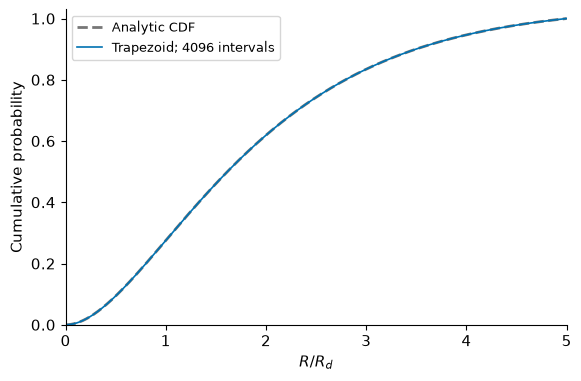

In [3]:
def cumulative_trapezoid(x, values):
    """第3章と同じ、各分点までの台形の和です。"""
    x, values = check_grid(x, values)
    integral = np.zeros_like(x)
    for j in range(len(x) - 1):
        area = 0.5 * (values[j] + values[j + 1]) * (x[j + 1] - x[j])
        integral[j + 1] = integral[j] + area
    return integral

def build_radial_cdf(rd, rmax, n_panels):
    check_positive(rd, "rd")
    check_positive(rmax, "rmax")
    check_integer(n_panels, "n_panels")
    radius_grid = np.linspace(0.0, rmax, n_panels + 1)
    weight = radius_grid * np.exp(-radius_grid / rd)
    ### BEGIN SOLUTION
    cumulative = cumulative_trapezoid(radius_grid, weight)
    if not np.isfinite(cumulative[-1]) or cumulative[-1] <= 0.0:
        raise ValueError("The normalization must be positive and finite.")
    cdf = cumulative / cumulative[-1]
    ### END SOLUTION
    if np.any(np.diff(cdf) <= 0.0):
        raise ValueError("The inverse CDF needs strictly increasing values; revise the grid/range.")
    return radius_grid, cdf

radius_grid, cdf = build_radial_cdf(rd, rmax, n_cdf)
cdf_node_error = np.max(np.abs(cdf - disk_cdf_exact(radius_grid, rd, rmax)))
print(f"CDF node error = {cdf_node_error:.6e}")
fig, ax = plt.subplots(figsize=(5.7, 3.7), layout="constrained")
ax.plot(radius_grid / rd, disk_cdf_exact(radius_grid, rd, rmax), color=GRAY, ls="--", lw=2, label="Analytic CDF")
ax.plot(radius_grid / rd, cdf, color=BLUE, lw=1.2, label=f"Trapezoid; {n_cdf} intervals")
ax.set(xlabel=r"$R/R_d$", ylabel="Cumulative probability", xlim=(0, rmax / rd), ylim=(0, 1.03))
ax.legend(fontsize=9)
save_figure(fig, "ch04_cdf")

## 3. 分点の間を読む：線形補間
$x_j\leq x\leq x_{j+1}$なら、$\lambda=(x-x_j)/(x_{j+1}-x_j)$を使い、
$$y(x)\simeq (1-\lambda)y_j+\lambda y_{j+1}$$
とします。まず一つの点について区間を探して計算します。その後で`np.interp`と比較します。
ここでは表の外の外挿を認めません。

Radius at CDF=0.5: manual=4.843929332, NumPy=4.843929332 kpc


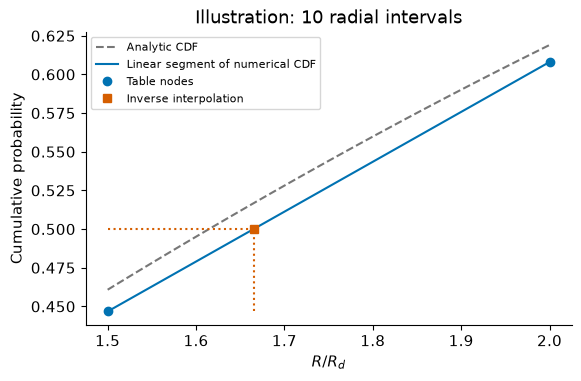

In [4]:
def linear_interp_one(x, xp, fp):
    """一つの点を補間します。本文 eq:ch4-linear-interpolation。"""
    xp, fp = check_grid(xp, fp)
    if not np.isfinite(x) or x < xp[0] or x > xp[-1]:
        raise ValueError("Interpolate only within the finite table range.")
    if x == xp[-1]:
        return float(fp[-1])
    for j in range(len(xp) - 1):
        if xp[j] <= x <= xp[j + 1]:
            ### BEGIN SOLUTION
            fraction = (x - xp[j]) / (xp[j + 1] - xp[j])
            return (1.0 - fraction) * fp[j] + fraction * fp[j + 1]
            ### END SOLUTION
    raise RuntimeError("No interpolation interval was found.")

# F -> R と表の役割を交換します。cdfは狭義単調増加でなければなりません。
u_demo = 0.5
radius_demo = linear_interp_one(u_demo, cdf, radius_grid)
radius_numpy = np.interp(u_demo, cdf, radius_grid)
print(f"Radius at CDF=0.5: manual={radius_demo:.9f}, NumPy={radius_numpy:.9f} kpc")

coarse_r, coarse_f = build_radial_cdf(rd, rmax, 10)
j = np.searchsorted(coarse_f, u_demo) - 1
r_line = np.linspace(coarse_r[j], coarse_r[j + 1], 101)
f_line = np.interp(r_line, coarse_r, coarse_f)
r_linear_demo = linear_interp_one(u_demo, coarse_f, coarse_r)
fig, ax = plt.subplots(figsize=(5.7, 3.7), layout="constrained")
ax.plot(r_line / rd, disk_cdf_exact(r_line, rd, rmax), color=GRAY, ls="--", label="Analytic CDF")
ax.plot(r_line / rd, f_line, color=BLUE, label="Linear segment of numerical CDF")
ax.plot(coarse_r[j:j + 2] / rd, coarse_f[j:j + 2], "o", color=BLUE, label="Table nodes")
ax.plot([coarse_r[j] / rd, r_linear_demo / rd], [u_demo, u_demo], color=VERMILLION, ls=":")
ax.plot([r_linear_demo / rd] * 2, [coarse_f[j], u_demo], color=VERMILLION, ls=":")
ax.plot(r_linear_demo / rd, u_demo, "s", color=VERMILLION, label="Inverse interpolation")
ax.set(xlabel=r"$R/R_d$", ylabel="Cumulative probability", title="Illustration: 10 radial intervals")
ax.legend(fontsize=8, loc="upper left")
save_figure(fig, "ch04_interpolation")

## 4. 補間表の誤差を、乱数を使わずに確認する
表の分割数だけを変え、毎回同じ確率$u$を逆変換します。
$\widehat R(u)$を独立な解析CDFに戻し、$\max|F(\widehat R(u))-u|$を測ります。
同じ数値表へ戻すだけでは、表そのものの近似誤差を検出できません。

CDF table: intervals, node error, inverse probability error, observed order
   32  1.522951e-03  2.449924e-03  --
   64  3.803485e-04  6.978569e-04  1.8117
  128  9.510060e-05  1.854256e-04  1.9121
  256  2.377398e-05  4.803834e-05  1.9486
  512  5.943667e-06  1.121660e-05  2.0986
Standard inverse probability error = 1.762643e-07


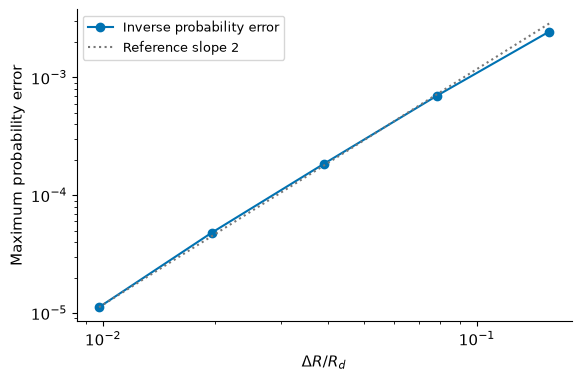

In [5]:
u_check = np.linspace(0.0, 1.0, 20001)
cdf_rows = []
for count in [32, 64, 128, 256, 512]:
    nodes, values = build_radial_cdf(rd, rmax, count)
    node_error = np.max(np.abs(values - disk_cdf_exact(nodes, rd, rmax)))
    inverted = np.interp(u_check, values, nodes)
    probability_error = np.max(np.abs(disk_cdf_exact(inverted, rd, rmax) - u_check))
    cdf_rows.append([count, rmax / count, node_error, probability_error])
cdf_convergence = np.asarray(cdf_rows)
cdf_orders = np.log2(cdf_convergence[:-1, 3] / cdf_convergence[1:, 3])
standard_inverse_error = np.max(np.abs(disk_cdf_exact(np.interp(u_check, cdf, radius_grid), rd, rmax) - u_check))
print("CDF table: intervals, node error, inverse probability error, observed order")
for k, row in enumerate(cdf_convergence):
    order = "--" if k == 0 else f"{cdf_orders[k - 1]:.4f}"
    print(f"{int(row[0]):5d}  {row[2]:.6e}  {row[3]:.6e}  {order}")
print(f"Standard inverse probability error = {standard_inverse_error:.6e}")
fig, ax = plt.subplots(figsize=(5.7, 3.7), layout="constrained")
h = cdf_convergence[:, 1] / rd
errors = cdf_convergence[:, 3]
ax.loglog(h, errors, "o-", color=BLUE, label="Inverse probability error")
ax.loglog(h, errors[-1] * (h / h[-1])**2, ":", color=GRAY, label="Reference slope 2")
ax.set(xlabel=r"$\Delta R/R_d$", ylabel="Maximum probability error")
ax.legend(fontsize=9)
save_figure(fig, "ch04_cdf_convergence")

## 5. 乱数から位置と速度を作る
各粒子について、独立な一様乱数$u_i,w_i$を使い、$R_i=F^{-1}(u_i)$、$\phi_i=2\pi w_i$とします。
$$x_i=R_i\cos\phi_i,\quad y_i=R_i\sin\phi_i,\quad
v_{x,i}=-s v_c(R_i)\sin\phi_i,\quad v_{y,i}=s v_c(R_i)\cos\phi_i.$$
$s_{\rm rot}=\pm1$は回転方向です。ここでは遭遇軌道がないのでprograde / retrogradeとは呼びません。
粒子同士の引力を計算せず、$v_c$はPlummer球だけから求めます。

In [6]:
def circular_speed_plummer(radius, mass, a):
    radius = np.asarray(radius, dtype=float)
    return np.sqrt(G * mass * radius**2 / (radius**2 + a**2)**1.5)


def potential_plummer(radius, mass, a):
    return -G * mass / np.sqrt(np.asarray(radius)**2 + a**2)

def make_disk(n_particles, mass, a, rd, rmax, spin, rng, n_panels=4096):
    check_integer(n_particles, "n_particles")
    check_positive(mass, "mass")
    check_positive(a, "a")
    if isinstance(spin, (bool, np.bool_)) or spin not in (-1, +1):
        raise ValueError("spin must be +1 or -1.")
    nodes, values = build_radial_cdf(rd, rmax, n_panels)
    uniform = rng.random((n_particles, 2))
    radius = np.interp(uniform[:, 0], values, nodes)
    phi = 2.0 * np.pi * uniform[:, 1]
    vc = circular_speed_plummer(radius, mass, a)
    ### BEGIN SOLUTION
    pos = np.column_stack((radius * np.cos(phi), radius * np.sin(phi)))
    vel = spin * np.column_stack((-vc * np.sin(phi), vc * np.cos(phi)))
    ### END SOLUTION
    return np.column_stack((pos, vel)), radius, phi

rng = np.random.default_rng(seed)
state0, radius0, phi0 = make_disk(n_particles, mass, a, rd, rmax, spin, rng, n_cdf)
print(f"state0.shape = {state0.shape}; min/max R = {radius0.min():.6f}, {radius0.max():.6f} kpc")
np.savez_compressed(DATADIR / "disk_initial.npz", state=state0, radius=radius0, phi=phi0)

state0.shape = (1000, 4); min/max R = 0.100153, 14.950926 kpc


## 6. 初期分布を確かめる
半径を並べて経験CDFを作ります。有限個の乱数では解析CDFと完全には一致しません。
面密度の推定には、円環の面積$\pi(R_{j+1}^2-R_j^2)$で割る必要があります。
粒子の単純な重心を強制的に原点へ戻したり、速度の平均を引いたりはしません。
それらの処理は、固定されたPlummer中心に対する円軌道初期条件を変えてしまいます。

Initial empirical CDF distance D_N = 0.029414


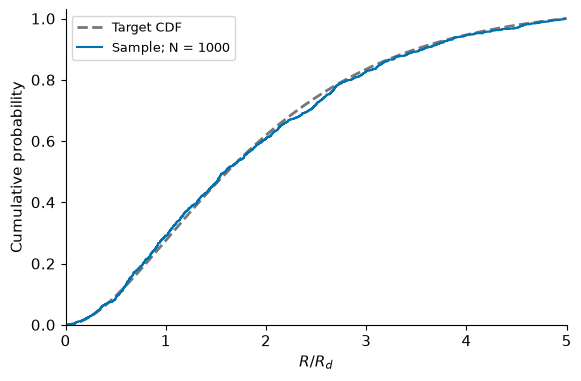

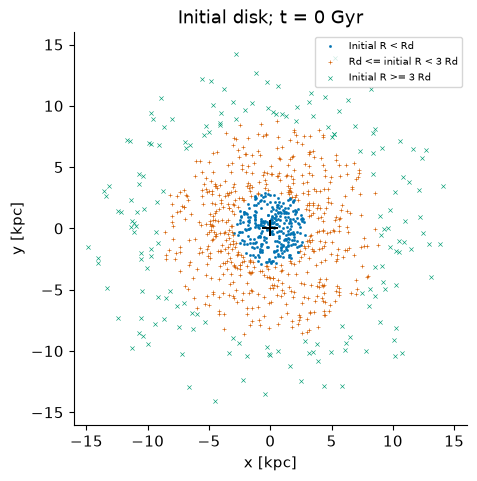

In [7]:
def empirical_cdf_distance(radius, rd, rmax):
    sorted_radius = np.sort(np.asarray(radius))
    n = len(sorted_radius)
    target = disk_cdf_exact(sorted_radius, rd, rmax)
    right = np.arange(1, n + 1) / n
    left = np.arange(n) / n
    return max(np.max(np.abs(right - target)), np.max(np.abs(left - target)))

def surface_number_profile(radius, edges):
    """全粒子数で規格化した、円環ごとの数面密度 [kpc^-2]。"""
    counts, _ = np.histogram(radius, bins=edges)
    ### BEGIN SOLUTION
    area = np.pi * (edges[1:]**2 - edges[:-1]**2)
    density = counts / (len(radius) * area)
    ### END SOLUTION
    return density, counts, area

cdf_sample_error = empirical_cdf_distance(radius0, rd, rmax)
print(f"Initial empirical CDF distance D_N = {cdf_sample_error:.6f}")
sorted_radius = np.sort(radius0)
fig, ax = plt.subplots(figsize=(5.7, 3.7), layout="constrained")
ax.plot(radius_grid / rd, disk_cdf_exact(radius_grid, rd, rmax), color=GRAY, ls="--", lw=2, label="Target CDF")
ax.step(np.r_[0.0, sorted_radius / rd], np.arange(n_particles + 1) / n_particles, where="post", color=BLUE, label=f"Sample; N = {n_particles}")
ax.set(xlabel=r"$R/R_d$", ylabel="Cumulative probability", xlim=(0, rmax / rd), ylim=(0, 1.03))
ax.legend(fontsize=9)
save_figure(fig, "ch04_empirical_cdf")

edges = np.linspace(0.0, rmax, 16)
profile0, counts0, area = surface_number_profile(radius0, edges)
centers = 0.5 * (edges[:-1] + edges[1:])
p_bin = np.diff(disk_cdf_exact(edges, rd, rmax))
expected_profile = p_bin / area


def plot_disk(state, initial_radius, title, name):
    fig, ax = plt.subplots(figsize=(5.1, 4.7), layout="constrained")
    groups = [(initial_radius < rd, BLUE, ".", "Initial R < Rd"),
              ((initial_radius >= rd) & (initial_radius < 3.0 * rd), VERMILLION, "+", "Rd <= initial R < 3 Rd"),
              (initial_radius >= 3.0 * rd, GREEN, "x", "Initial R >= 3 Rd")]
    for mask, color, marker, label in groups:
        ax.scatter(state[mask, 0], state[mask, 1], s=9, color=color, marker=marker, linewidths=0.45, label=label)
    ax.plot(0.0, 0.0, "k+", ms=11, mew=1.4)
    ax.set(xlabel="x [kpc]", ylabel="y [kpc]", xlim=(-1.07 * rmax, 1.07 * rmax), ylim=(-1.07 * rmax, 1.07 * rmax), title=title)
    ax.set_aspect("equal")
    ax.legend(loc="upper right", fontsize=7.5)
    save_figure(fig, name)


plot_disk(state0, radius0, "Initial disk; t = 0 Gyr", "ch04_disk_initial")

## 7. 1粒子の重力を多数粒子へ拡張する
新しい物理は加えません。第3章の式を、粒子ごとに独立に評価します。
`pos`は$(N,2)$、`r2`は$(N,)$です。`[:, None]`を使って分母を$(N,1)$にすると、
各行の$x,y$をその粒子の同じ分母で割れます。$N\times N$の粒子対配列は作りません。

In [8]:
def acceleration_plummer_loop(pos, mass, a):
    acc = np.empty_like(pos)
    for i in range(len(pos)):
        x, y = pos[i]
        r2 = x**2 + y**2
        acc[i, 0] = -G * mass * x / (r2 + a**2)**1.5
        acc[i, 1] = -G * mass * y / (r2 + a**2)**1.5
    return acc

def acceleration_plummer(pos, mass, a):
    """固定Plummer球から各粒子への加速度。本文 eq:ch4-acceleration。"""
    ### BEGIN SOLUTION
    r2 = np.sum(pos**2, axis=1)
    acc = -G * mass * pos / (r2 + a**2)[:, None]**1.5
    ### END SOLUTION
    return acc

acc_loop = acceleration_plummer_loop(state0[:, :2], mass, a)
acc_vector = acceleration_plummer(state0[:, :2], mass, a)
vector_difference = np.max(np.abs(acc_loop - acc_vector)) / (G * mass / a**2)
print(f"Loop vs. vectorized acceleration / (GM/a^2): {vector_difference:.3e}")

Loop vs. vectorized acceleration / (GM/a^2): 7.278e-17


## 8. KDKと保存間隔
KDKの式は第3章から変えません。位置と速度を全粒子分まとめて更新します。
最後の半kick後の速度を保存し、次のステップでは計算済みの加速度を再利用します。
保存間隔を粗くするのはメモリ節約であり、時間積分を粗くする操作ではありません。

Integration: 0.091 s (this environment only)
Stored shape = (301, 1000, 4); memory = 9.632 MB (decimal)
Force evaluations = 3001; time step = 0.200 Myr


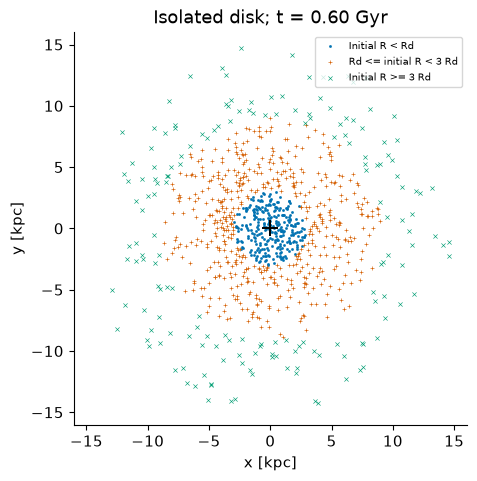

In [9]:
def leapfrog_step(acceleration, pos, vel, acc, dt, mass, a):
    vel_half = vel + 0.5 * dt * acc
    pos_new = pos + dt * vel_half
    acc_new = acceleration(pos_new, mass, a)
    vel_new = vel_half + 0.5 * dt * acc_new
    return pos_new, vel_new, acc_new


def prepare_history(state0, t_end, n_steps, save_every):
    check_integer(n_steps, "n_steps")
    check_integer(save_every, "save_every")
    check_positive(t_end, "t_end")
    state = np.array(state0, dtype=float, copy=True)
    if state.ndim != 2 or state.shape[1] != 4 or len(state) < 1 or not np.all(np.isfinite(state)):
        raise ValueError("state0 must be a finite array with shape (N, 4), N >= 1.")
    saved_steps = np.unique(np.r_[np.arange(0, n_steps + 1, save_every), n_steps])
    dt = t_end / n_steps
    times = saved_steps * dt
    history = np.empty((len(saved_steps), len(state), 4))
    history[0] = state
    return state, saved_steps, times, history, dt


def integrate_leapfrog(acceleration, state0, t_end, n_steps, mass, a, save_every=10):
    check_positive(mass, "mass")
    check_positive(a, "a")
    state, saved_steps, times, history, dt = prepare_history(state0, t_end, n_steps, save_every)
    pos, vel = state[:, :2].copy(), state[:, 2:].copy()
    acc = acceleration(pos, mass, a)
    output_index = 1
    for n in range(n_steps):
        pos, vel, acc = leapfrog_step(acceleration, pos, vel, acc, dt, mass, a)
        if not np.all(np.isfinite(pos)) or not np.all(np.isfinite(vel)):
            raise FloatingPointError("Non-finite state; check the model and time step.")
        if n + 1 == saved_steps[output_index]:
            history[output_index] = np.column_stack((pos, vel))
            output_index += 1
    return times, history

start = perf_counter()
times, history = integrate_leapfrog(acceleration_plummer, state0, t_end, n_steps, mass, a, save_every)
wall_seconds = perf_counter() - start
print(f"Integration: {wall_seconds:.3f} s (this environment only)")
print(f"Stored shape = {history.shape}; memory = {history.nbytes / 1e6:.3f} MB (decimal)")
print(f"Force evaluations = {n_steps + 1}; time step = {dt * 1000:.3f} Myr")
plot_disk(history[-1], radius0, f"Isolated disk; t = {t_end:.2f} Gyr", "ch04_disk_final")

## 9. 半径分布・保存量・同時刻の位置を確認する
角速度は$\Omega(R)=\sqrt{GM}/(R^2+a^2)^{3/4}$です。各粒子の**初期半径**から一度だけ求めます。
半径が違えば角速度も違います。連続的な軸対称の数密度は変わらなくても、個々の点の模様は変わります。
下の最大誤差は**保存した時刻と全粒子**について取ります。保存しなかった時刻の最大値ではありません。

Saved-time errors [position/Rd, radius/Rd, relative energy, angular/scale]:
[5.45866299e-04 4.73291442e-05 2.19410855e-09 5.00336332e-14]
CDF distance: initial=0.029414, final=0.029420


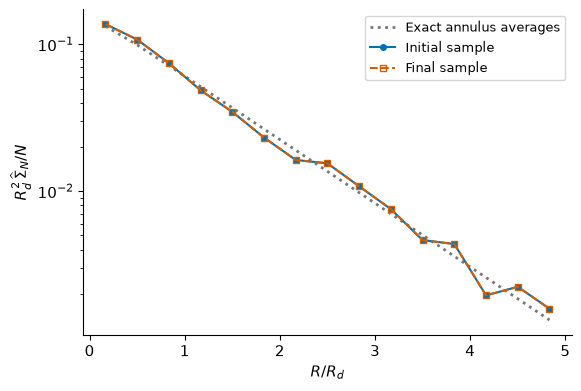

In [10]:
def exact_disk_positions(times, state0, mass, a, spin):
    """円運動の初期条件にだけ使う、同時刻の解析位置です。"""
    pos0 = state0[:, :2]
    radius2 = np.sum(pos0**2, axis=1)
    omega = np.sqrt(G * mass) / (radius2 + a**2)**0.75
    angle = spin * np.asarray(times)[:, None] * omega[None, :]
    c, s = np.cos(angle), np.sin(angle)
    x = pos0[None, :, 0] * c - pos0[None, :, 1] * s
    y = pos0[None, :, 0] * s + pos0[None, :, 1] * c
    return np.stack((x, y), axis=2)

def diagnostics(history, mass, a):
    pos, vel = history[:, :, :2], history[:, :, 2:]
    radius = np.sqrt(np.sum(pos**2, axis=2))
    energy = 0.5 * np.sum(vel**2, axis=2) + potential_plummer(radius, mass, a)
    angular = pos[:, :, 0] * vel[:, :, 1] - pos[:, :, 1] * vel[:, :, 0]
    return radius, energy, angular

def disk_error_metrics(times, history, state0, mass, a, rd, spin):
    radius, energy, angular = diagnostics(history, mass, a)
    exact = exact_disk_positions(times, state0, mass, a, spin)
    position_error = np.max(np.linalg.norm(history[:, :, :2] - exact, axis=2)) / rd
    radius_error = np.max(np.abs(radius - radius[0])) / rd
    energy_error = np.max(np.abs(energy - energy[0]) / np.abs(energy[0]))
    angular_scale = rd * circular_speed_plummer(rd, mass, a)
    angular_error = np.max(np.abs(angular - angular[0])) / angular_scale
    return np.array([position_error, radius_error, energy_error, angular_error])

errors_standard = disk_error_metrics(times, history, state0, mass, a, rd, spin)
radius_history, energy_history, angular_history = diagnostics(history, mass, a)
profile_final, counts_final, _ = surface_number_profile(radius_history[-1], edges)
print("Saved-time errors [position/Rd, radius/Rd, relative energy, angular/scale]:")
print(errors_standard)
print(f"CDF distance: initial={cdf_sample_error:.6f}, final={empirical_cdf_distance(radius_history[-1], rd, rmax):.6f}")
fig, ax = plt.subplots(figsize=(5.7, 3.8), layout="constrained")
ax.plot(centers / rd, expected_profile * rd**2, color=GRAY, ls=":", lw=2, label="Exact annulus averages")
ax.plot(centers / rd, profile0 * rd**2, "o-", color=BLUE, ms=4, label="Initial sample")
ax.plot(centers / rd, profile_final * rd**2, "s--", color=VERMILLION, mfc="none", ms=5, label="Final sample")
ax.set(xlabel=r"$R/R_d$", ylabel=r"$R_d^2\,\widehat\Sigma_N/N$", yscale="log")
ax.legend(fontsize=9)
save_figure(fig, "ch04_surface_profile")

## 10. 時間刻みだけを変える
全計算で同じ`state0`と終時刻を使います。CDFや乱数を作り直しません。
保存時刻も151個の同じ時刻にそろえ、同時刻の解析位置と比較します。
ここでの`N_step`と、CDF表の`n_cdf`、粒子数`N`は別です。

Time-step study: steps, dt [Myr], position/Rd, observed order
  750  0.8000  8.739061e-03  --
 1500  0.4000  2.183726e-03  2.00069
 3000  0.2000  5.458663e-04  2.00017
 6000  0.1000  1.364625e-04  2.00004


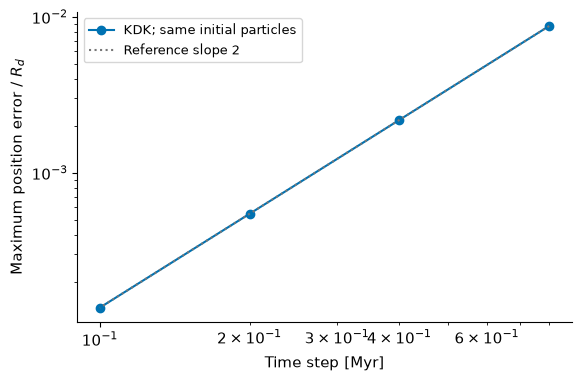

In [11]:
orbit_rows = []
for count in [750, 1500, 3000, 6000]:
    t_check, h_check = integrate_leapfrog(acceleration_plummer, state0, t_end, count, mass, a, count // 150)
    errors = disk_error_metrics(t_check, h_check, state0, mass, a, rd, spin)
    orbit_rows.append([count, t_end / count, *errors])
orbit_convergence = np.asarray(orbit_rows)
orbit_orders = np.log2(orbit_convergence[:-1, 2] / orbit_convergence[1:, 2])
print("Time-step study: steps, dt [Myr], position/Rd, observed order")
for k, row in enumerate(orbit_convergence):
    order = "--" if k == 0 else f"{orbit_orders[k - 1]:.5f}"
    print(f"{int(row[0]):5d}  {1000 * row[1]:.4f}  {row[2]:.6e}  {order}")
fig, ax = plt.subplots(figsize=(5.7, 3.7), layout="constrained")
h = orbit_convergence[:, 1] * 1000
errors = orbit_convergence[:, 2]
ax.loglog(h, errors, "o-", color=BLUE, label="KDK; same initial particles")
ax.loglog(h, errors[-1] * (h / h[-1])**2, ":", color=GRAY, label="Reference slope 2")
ax.set(xlabel="Time step [Myr]", ylabel=r"Maximum position error / $R_d$")
ax.legend(fontsize=9)
save_figure(fig, "ch04_orbit_convergence")

## 11. 粒子数・乱数seed・回転方向
粒子数を増やしても、すでに置いた1粒子への力は変わりません。変わるのは分布を表す標本です。
同じseedだけで「必ず単調に改善する」と判断せず、8個のseedでもCDFのずれを比べます。
回転方向の比較では同じ位置標本を使います。今回は初期速度の符号だけが変わります。

In [12]:
sampling_rows = []
for number in [250, 1000, 4000]:
    distances = []
    for trial_seed in range(42, 50):
        trial_rng = np.random.default_rng(trial_seed)
        uniforms = trial_rng.random((number, 2))
        samples = np.interp(uniforms[:, 0], cdf, radius_grid)
        distances.append(empirical_cdf_distance(samples, rd, rmax))
    sampling_rows.append([number, distances[0], np.mean(distances), np.min(distances), np.max(distances)])
sampling_summary = np.asarray(sampling_rows)
print("Sampling [N, D(seed42), mean D, min D, max D] for seeds 42...49:")
print(sampling_summary)

reverse0, _, _ = make_disk(n_particles, mass, a, rd, rmax, -1, np.random.default_rng(seed), n_cdf)
t_reverse, h_reverse = integrate_leapfrog(acceleration_plummer, reverse0, t_end, n_steps, mass, a, save_every)
reverse_errors = disk_error_metrics(t_reverse, h_reverse, reverse0, mass, a, rd, -1)
r_reverse, e_reverse, l_reverse = diagnostics(h_reverse, mass, a)
print(f"Reverse spin: same initial positions = {np.array_equal(state0[:, :2], reverse0[:, :2])}")
print(f"Reverse spin position error/Rd = {reverse_errors[0]:.6e}")

Sampling [N, D(seed42), mean D, min D, max D] for seeds 42...49:
[[2.50000000e+02 6.33921218e-02 5.20602842e-02 3.12916648e-02
  6.65331566e-02]
 [1.00000000e+03 2.94135553e-02 3.25647284e-02 1.76726632e-02
  5.59069149e-02]
 [4.00000000e+03 9.38172877e-03 1.28195646e-02 7.85592998e-03
  1.84570610e-02]]
Reverse spin: same initial positions = True
Reverse spin position error/Rd = 5.458663e-04


## 12. 演習と発展
**確認4.1–4.3：** 円環の面積、補間式、有限範囲のCDF規格化を本文の式で確認します。
**応用4.4：** `N=250,1000,4000`、seed=42...49でCDFのずれを比較します。表は上で計算済みです。
**応用4.5：** `save_every`だけを変え、同じ終点になるか確かめます。時間刻みの変更とは別です。
**応用4.6：** 回転方向を反転します。初期エネルギーは同じ、角運動量の符号は逆です。
**発展4.7：** 初期速度を円運動速度の80%にします。これは初期条件を変える実験です。
下の発展計算には円軌道の解析解を誤差として使いません。エネルギーと角運動量を確認します。

In [13]:
subcircular0 = state0.copy()
subcircular0[:, 2:] *= 0.8
t_sub, h_sub = integrate_leapfrog(acceleration_plummer, subcircular0, t_end, n_steps, mass, a, save_every)
r_sub, e_sub, l_sub = diagnostics(h_sub, mass, a)
sub_energy_error = np.max(np.abs(e_sub - e_sub[0]) / np.abs(e_sub[0]))
sub_angular_error = np.max(np.abs(l_sub - l_sub[0])) / (rd * circular_speed_plummer(rd, mass, a))
print(f"Subcircular disk: final median radius = {np.median(r_sub[-1]):.6f} kpc")
print(f"Subcircular disk: relative energy error = {sub_energy_error:.6e}")

# 第3章の二分法の考え方を使った、解析CDFの中央値の確認です。
def quantile_by_bisection(probability, rd, rmax, tolerance=1.0e-10):
    lower, upper = 0.0, rmax
    for _ in range(100):
        middle = 0.5 * (lower + upper)
        if upper - lower <= 2.0 * tolerance:
            return middle
        if disk_cdf_exact(middle, rd, rmax) < probability:
            lower = middle
        else:
            upper = middle
    raise RuntimeError("The quantile check did not converge.")


half_exact = quantile_by_bisection(0.5, rd, rmax)
t0_core = 2.0 * np.pi * np.sqrt(a**3 / (G * mass))
summary = {
    "chapter_version": "1.0", "mass_Msun": mass, "a_kpc": a, "rd_kpc": rd, "rmax_kpc": rmax,
    "n_particles": n_particles, "n_cdf": n_cdf, "seed": seed, "spin": spin,
    "t_end_Gyr": t_end, "n_steps": n_steps, "dt_Myr": dt * 1000, "save_every": save_every,
    "saved_count": len(times), "history_MB": history.nbytes / 1e6, "force_calls": n_steps + 1,
    "runtime_seconds_environment_specific": wall_seconds, "numpy_version": np.__version__,
    "c_q": c_q, "fraction_inside_rd": float(disk_cdf_exact(rd, rd, rmax)),
    "cdf_node_error": float(cdf_node_error), "inverse_probability_error": float(standard_inverse_error),
    "cdf_sample_error": float(cdf_sample_error), "cdf_final_error": float(empirical_cdf_distance(radius_history[-1], rd, rmax)),
    "half_interpolated_kpc": float(radius_demo), "half_exact_kpc": float(half_exact),
    "half_sample_kpc": float(np.median(radius0)), "min_radius_kpc": float(radius0.min()),
    "max_radius_kpc": float(radius0.max()), "central_period_Gyr": t0_core,
    "cdf_convergence": cdf_convergence.tolist(), "cdf_orders": cdf_orders.tolist(),
    "standard_errors": errors_standard.tolist(), "vector_difference": float(vector_difference),
    "orbit_convergence": orbit_convergence.tolist(), "orbit_orders": orbit_orders.tolist(),
    "sampling_summary": sampling_summary.tolist(), "reverse_errors": reverse_errors.tolist(),
    "subcircular_final_median_kpc": float(np.median(r_sub[-1])), "subcircular_energy_error": float(sub_energy_error),
    "subcircular_angular_error": float(sub_angular_error)
}
_ = (DATADIR / "validation.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
np.savetxt(DATADIR / "cdf_table.csv", np.column_stack((radius_grid, cdf)), delimiter=",", header="R_kpc,F_numeric", comments="")
np.savetxt(DATADIR / "cdf_convergence.csv", cdf_convergence, delimiter=",", header="intervals,dR_kpc,node_error,inverse_probability_error", comments="")
np.savetxt(DATADIR / "orbit_convergence.csv", orbit_convergence, delimiter=",", header="steps,dt_Gyr,position_error,radius_error,energy_error,angular_error", comments="")
np.savetxt(DATADIR / "sampling_summary.csv", sampling_summary, delimiter=",", header="N,D_seed42,D_mean,D_min,D_max", comments="")
np.savetxt(DATADIR / "surface_profile.csv", np.column_stack((edges[:-1], edges[1:], counts0, counts_final, profile0, profile_final, expected_profile)), delimiter=",", header="R_lower,R_upper,N_initial,N_final,Sigma_initial_perN,Sigma_final_perN,Sigma_exact_perN", comments="")
np.savetxt(DATADIR / "radius_evolution.csv", np.column_stack((times, np.median(radius_history, axis=1), np.median(r_sub, axis=1))), delimiter=",", header="t_Gyr,median_R_circular,median_R_subcircular", comments="")

assert cdf[0] == 0.0 and cdf[-1] == 1.0 and np.all(np.diff(cdf) > 0.0)
assert np.all(radius0 >= 0.0) and np.all(radius0 <= rmax)
assert np.isfinite(history).all() and errors_standard[0] < 0.02
assert errors_standard[2] < 1.0e-5 and errors_standard[3] < 1.0e-10
assert 1.9 < orbit_orders[-1] < 2.1
print("Standard-model checks passed. Data directory:", DATADIR)

Subcircular disk: final median radius = 4.025966 kpc
Subcircular disk: relative energy error = 1.550126e-05
Standard-model checks passed. Data directory: output/chap04/data


## 13. 保存済みの履歴をアニメーションにする
表示フレームの間隔は物理的な時間刻みではありません。数値積分を再実行せず、保存済みの位置を使います。
見やすさのため、全粒子のうち最初の3個だけを別のマーカーで追跡します。これらに特別な力は働きません。
動画を生成しない場合は、最初のセルの`MAKE_ANIMATION`を`False`にします。

In [14]:
if MAKE_ANIMATION:
    from IPython.display import HTML, display
    from matplotlib.animation import FuncAnimation

    frame_ids = np.unique(np.r_[np.arange(0, len(times), 5), len(times) - 1])
    fig, ax = plt.subplots(figsize=(5.0, 4.8), layout="constrained")
    cloud = ax.scatter(history[0, :, 0], history[0, :, 1], s=4, color=BLUE, alpha=0.65, linewidths=0)
    tracked = [ax.plot([], [], marker=m, color=c, ls="none", ms=7)[0]
               for m, c in [("s", VERMILLION), ("^", GREEN), ("x", "black")]]
    ax.plot(0.0, 0.0, "+", color="black", ms=9)
    label = ax.text(0.04, 0.95, "", transform=ax.transAxes)
    ax.set(xlabel="x [kpc]", ylabel="y [kpc]", xlim=(-1.07 * rmax, 1.07 * rmax), ylim=(-1.07 * rmax, 1.07 * rmax))
    ax.set_aspect("equal")

    def update_animation(frame):
        index = frame_ids[frame]
        cloud.set_offsets(history[index, :, :2])
        for particle, artist in enumerate(tracked):
            artist.set_data([history[index, particle, 0]], [history[index, particle, 1]])
        label.set_text(f"t = {times[index]:.3f} Gyr")
        return cloud, label, *tracked

    animation = FuncAnimation(fig, update_animation, frames=len(frame_ids), interval=70, blit=False)
    html = animation.to_jshtml(fps=14)
    (FIGDIR / "ch04_disk_animation.html").write_text(html, encoding="utf-8")
    display(HTML(html))
    plt.close(fig)
else:
    print("Animation is available in the completed Notebook.")

## 任意演習の実行状況を保存する
本章には任意演習のコードセルがないため、状態は `not_applicable` です。

In [15]:
save_exercise_results()
print("任意演習のコードセルはありません（not_applicable）。")

任意演習のコードセルはありません（not_applicable）。
